# 06 - Robustness

Do the conclusions survive when the main choices change? Two checks, both on
the development set with the same repeated cross-validation as before
(5 repeats × 5 folds, paired against the pick-only baseline):

1. **Without the age cut**: put back the players who debuted older than 25
2. **Shorter windows**: 10 and 15 games instead of 25. How early does the signal appear?

The model itself doesn't change (same ensemble, same settings). This runs
*before* the final test, so if something here called for a change it could
still be made honestly.

Window tables are built with `python src/build_rookie_window.py --window 10`
then `python src/build_features.py --window 10` (same for 15).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
import models as md
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2

apply_style()


def evaluate(table_name):
    """Repeated CV of the baseline and the ensemble on one table's development set."""
    dev = m.dev_set(md.add_pick_terms(m.load_table(table_name)))
    base, base_oof = m.repeated_cv(md.baseline, ["pick"], dev)
    model, model_oof = m.repeated_cv(md.ensemble, md.ALL, dev)
    return dev, base, model, base_oof, model_oof


def summary_row(base, model):
    return {
        "baseline RMSE": base["rmse"].mean(), "model RMSE": model["rmse"].mean(),
        "RMSE gain": base["rmse"].mean() - model["rmse"].mean(),
        "gain %": 100 * (1 - model["rmse"].mean() / base["rmse"].mean()),
        "baseline Spearman": base["spearman"].mean(), "model Spearman": model["spearman"].mean(),
        "beats baseline (of 25)": int((model["rmse"].values < base["rmse"].values).sum()),
    }

## 1. Without the age cut

The main analysis only models players aged 25 or younger at debut. Here the
older debutants (mostly draft-and-stash players like Scola and Navarro) come back.

In [2]:
dev_main, base_main, model_main, _, _ = evaluate("model_table")
dev_all, base_all, model_all, base_oof_all, model_oof_all = evaluate("model_table_all_ages")

age_cmp = pd.DataFrame({
    "Age cut (main)": summary_row(base_main, model_main),
    "No age cut": summary_row(base_all, model_all),
}).T
age_cmp.insert(0, "players", [len(dev_main), len(dev_all)])
age_cmp.round(3)

,players,baseline RMSE,model RMSE,RMSE gain,gain %,baseline Spearman,model Spearman,beats baseline (of 25)
Age cut (main),683,2.102,1.889,0.213,10.139,0.274,0.438,24.0
No age cut,691,2.094,1.878,0.215,10.293,0.271,0.439,24.0


In [3]:
old = dev_all[dev_all["age_at_debut"] > 25].assign(
    baseline_pred=base_oof_all, model_pred=model_oof_all)
old = old[["player_name", "draft_year", "pick", "age_at_debut", "mpg", m.TARGET,
           "baseline_pred", "model_pred"]]
print(f"Older debutants in the development set: {len(old)}")
print(f"Average error (actual - predicted): baseline {(old[m.TARGET] - old['baseline_pred']).mean():+.2f}, "
      f"model {(old[m.TARGET] - old['model_pred']).mean():+.2f}")
old.sort_values(m.TARGET, ascending=False).round(2)

Older debutants in the development set: 8
Average error (actual - predicted): baseline +0.12, model -0.08


,player_name,draft_year,pick,age_at_debut,mpg,target_vorp,baseline_pred,model_pred
374,Tiago Splitter,2007,28,26.0,11.14,2.9,0.69,1.30
144,Luis Scola,2002,55,27.0,18.64,2.1,0.38,0.96
627,Bernard James,2012,33,27.0,11.67,0.1,0.61,1.04
132,David Andersen,2002,36,29.0,13.48,0.0,0.57,0.47
145,Randy Holcomb,2002,56,26.0,2.50,0.0,0.38,0.01
134,Juan Carlos Navarro,2002,39,27.0,24.12,0.0,0.53,0.52
386,Derrick Byars,2007,42,27.0,18.50,0.0,0.48,1.39
438,Patrick Ewing,2008,43,26.0,2.71,0.0,0.48,0.08


**What to look for:** whether the model still beats the baseline by a similar
margin, and how the older players are predicted. They were cut because their first
games describe an already-formed player and their years 3-4 fall at 30+; if the
model systematically misses them, that supports the cut.

## 2. How early does the signal appear?

Same model, features computed over the first 10, 15 or 25 team games after the
debut. Shrinkage settings are unchanged, so short windows are automatically
pulled harder toward the average rookie (less sample).

In [4]:
WINDOWS = {10: "model_table_w10", 15: "model_table_w15", 25: "model_table"}
win_rows, win_tables = {}, {}
for w, name in WINDOWS.items():
    if w == 25:
        base, model = base_main, model_main
    else:
        _, base, model, _, _ = evaluate(name)
    win_rows[w] = summary_row(base, model)
    win_tables[w] = (base, model)
win_cmp = pd.DataFrame(win_rows).T
win_cmp.index.name = "window (team games)"
total_gain = win_cmp.loc[25, "RMSE gain"]
win_cmp["share of the 25-game gain"] = win_cmp["RMSE gain"] / total_gain
win_cmp.round(3)

,baseline RMSE,model RMSE,RMSE gain,gain %,baseline Spearman,model Spearman,beats baseline (of 25),share of the 25-game gain
window (team games),,,,,,,,
10,2.102,2.019,0.082,3.912,0.274,0.366,19.0,0.386
15,2.102,1.950,0.151,7.195,0.274,0.395,21.0,0.710
25,2.102,1.889,0.213,10.139,0.274,0.438,24.0,1.000


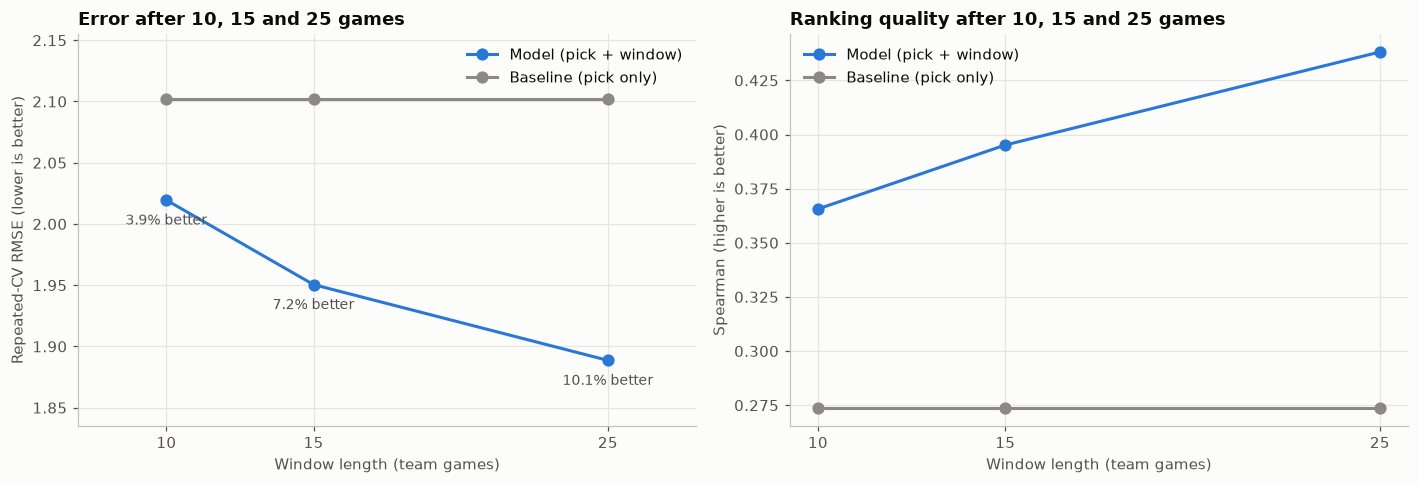

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ws = list(WINDOWS)

ax = axes[0]
ax.plot(ws, win_cmp["model RMSE"], color=BLUE, marker="o", markersize=7, label="Model (pick + window)")
ax.plot(ws, win_cmp["baseline RMSE"], color=NEUTRAL, marker="o", markersize=7, label="Baseline (pick only)")
for w in ws:
    ax.annotate(f"{win_cmp.loc[w, 'gain %']:.1f}% better", (w, win_cmp.loc[w, "model RMSE"]),
                xytext=(0, -16), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(ws)
ax.set_xlim(7, 28)
ax.set(title="Error after 10, 15 and 25 games", xlabel="Window length (team games)",
       ylabel="Repeated-CV RMSE (lower is better)")
ax.margins(y=0.25)
ax.legend()

ax = axes[1]
ax.plot(ws, win_cmp["model Spearman"], color=BLUE, marker="o", markersize=7, label="Model (pick + window)")
ax.plot(ws, win_cmp["baseline Spearman"], color=NEUTRAL, marker="o", markersize=7, label="Baseline (pick only)")
ax.set_xticks(ws)
ax.set(title="Ranking quality after 10, 15 and 25 games", xlabel="Window length (team games)",
       ylabel="Spearman (higher is better)")
ax.legend()
plt.tight_layout()
plt.show()

**What to look for:** how much of the 25-game improvement is already there after
10 games. A flat line means the signal appears very early (mostly the coach's
first minutes decisions); a steady drop means every extra game adds information.
The baseline is the same in all three (the pick doesn't depend on the window).

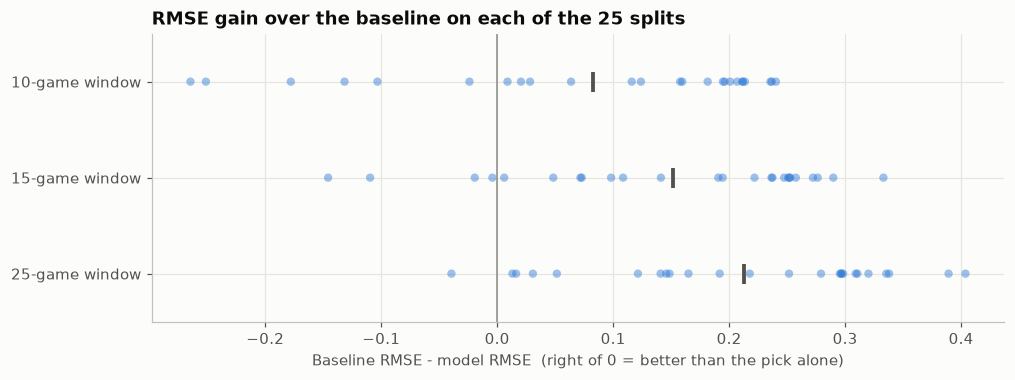

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, w in enumerate(ws):
    base, model = win_tables[w]
    gain = base["rmse"].values - model["rmse"].values
    ax.scatter(gain, [i] * len(gain), s=30, color=BLUE, alpha=0.45, edgecolor="none")
    ax.scatter(gain.mean(), i, s=160, marker="|", color=INK_2, linewidths=2.5)
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_yticks(range(len(ws)), [f"{w}-game window" for w in ws])
ax.set_ylim(len(ws) - 0.5, -0.5)
ax.set(title="RMSE gain over the baseline on each of the 25 splits",
       xlabel="Baseline RMSE - model RMSE  (right of 0 = better than the pick alone)")
plt.show()